In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task3-aqi-STACK.ipynb")

# Task 3: Visualizing AQI during the 2017 Thomas Fire in Santa Barbara County

This task covers topics on the lesson on [time series](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-7-time-series.html). 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATE THIS LINK**
https://github.com/MEDS-eds-220/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Make at least 5 commits. Generally, commit every time you finish a major step.** We'll check your repository and view the commit history.

- **Add comments for all your code.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data

In this task you will use [Air Quality Index (AQI)](https://www.airnow.gov/aqi/aqi-basics/) data from the [US Environmental Protection Agency](https://www.epa.gov) to visualize the impact on the AQI of the 2017 [Thomas Fire](https://en.wikipedia.org/wiki/Thomas_Fire) in Santa Barbara County. 

## FINAL CODE

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

## 1

a. Read the [Air Quality Index (AQI) Basics](https://www.airnow.gov/aqi/aqi-basics/) from the AirNow.gov portal.

b. Go to [EPA's website on Air Quality Data Collected at Outdoor Monitors Across the US](https://www.epa.gov/outdoor-air-quality-data). 

c. Under "Download Data", click on "Pre-generated Data Files".

d. Read the "About the data" section.

## 2
a. Back in the "Pre-generated Data Files" site, click on "Tables of Daily AQI".

b. Download the 2017 Daily AQI **by County** ZIP file `daily_aqi_by_county_2017.zip` and the 2018 Daily AQI **by County** ZIP file `daily_aqi_by_county_2018.zip`. Save both files in the same folder as this notebook.

We will be reading the data directly from the local ZIP files. Each ZIP file contains a single CSV that has been compressed to save space.

<!-- BEGIN QUESTION -->

c. In the next code cell read in the data from the local ZIP file using the [`pd.read_csv`] function with the `compression='zip'` parameter added and store it as `aqi_17`.

d. In the same cell, read in the data for the 2018 Daily AQI by County ZIP file and store it as `aqi_18`.

In [34]:
# Download packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read in data
aqi_17 = pd.read_csv('data/daily_aqi_by_county_2017.csv') # computer automatically unzipped data which is why 'compression=zip' was not applied
aqi_18 = pd.read_csv('data/daily_aqi_by_county_2018.csv')

<!-- END QUESTION -->

## 3
a. and b. Use the next two code cells to look at the head of both data frames. Store your results in `aqi_17_head` and `aqi_18_head`. 

In [3]:
# a.
# Collect some preliminary information by viewing the first 5 rows
aqi_17_head = aqi_17.head()
aqi_17_head

,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
0,Alabama,Baldwin,1,3,2017-01-01,28,Good,PM2.5,01-003-0010,1
1,Alabama,Baldwin,1,3,2017-01-04,29,Good,PM2.5,01-003-0010,1
2,Alabama,Baldwin,1,3,2017-01-10,25,Good,PM2.5,01-003-0010,1
3,Alabama,Baldwin,1,3,2017-01-13,40,Good,PM2.5,01-003-0010,1
4,Alabama,Baldwin,1,3,2017-01-16,22,Good,PM2.5,01-003-0010,1


In [4]:
# b.
aqi_18_head = aqi_18.head()
aqi_18_head

,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
0,Alabama,Baldwin,1,3,2018-01-02,42,Good,PM2.5,01-003-0010,1
1,Alabama,Baldwin,1,3,2018-01-05,45,Good,PM2.5,01-003-0010,1
2,Alabama,Baldwin,1,3,2018-01-08,20,Good,PM2.5,01-003-0010,1
3,Alabama,Baldwin,1,3,2018-01-11,25,Good,PM2.5,01-003-0010,1
4,Alabama,Baldwin,1,3,2018-01-14,33,Good,PM2.5,01-003-0010,1


In [5]:
grader.check("q3_a")

q3_a results: All test cases passed!

<!-- BEGIN QUESTION -->

c. Use this code cell to make some other preliminary data exploration of your choosing.

In [6]:
# View rows and columns of aqi_17
aqi_17.shape
print(aqi_17.shape)

(326801, 10)


In [7]:
# View rows and columns of aqi_18
aqi_18.shape
print(aqi_18.shape)

(327541, 10)


In [8]:
# View column names of aqi_17
aqi_17.columns
print(aqi_17.columns)

Index(['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI',
       'Category', 'Defining Parameter', 'Defining Site',
       'Number of Sites Reporting'],
      dtype='object')


In [9]:
# View column names of aqi_18
aqi_18.columns
print(aqi_18.columns)

Index(['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI',
       'Category', 'Defining Parameter', 'Defining Site',
       'Number of Sites Reporting'],
      dtype='object')


In [10]:
# Check data type of each column of aqi_17
aqi_17.dtypes
print(aqi_17.dtypes)

State Name                   object
county Name                  object
State Code                    int64
County Code                   int64
Date                         object
AQI                           int64
Category                     object
Defining Parameter           object
Defining Site                object
Number of Sites Reporting     int64
dtype: object


In [11]:
# Check data type of each column of aqi_18
aqi_18.dtypes
print(aqi_18.dtypes)

State Name                   object
county Name                  object
State Code                    int64
County Code                   int64
Date                         object
AQI                           int64
Category                     object
Defining Parameter           object
Defining Site                object
Number of Sites Reporting     int64
dtype: object


In [12]:
# View distinct values in the State column of aqi_17
aqi_17['State Name'].unique()

array(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California',
       'Colorado', 'Connecticut', 'Country Of Mexico', 'Delaware',
       'District Of Columbia', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Jersey', 'New Mexico', 'New York',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Puerto Rico', 'Rhode Island', 'South Carolina',
       'South Dakota', 'Tennessee', 'Texas', 'Utah', 'Vermont',
       'Virgin Islands', 'Virginia', 'Washington', 'West Virginia',
       'Wisconsin', 'Wyoming'], dtype=object)

In [13]:
# View distinct values in the AQI column of aqi_18
aqi_18['AQI'].unique()

array([  42,   45,   20,   25,   33,   31,   55,   18,   53,   28,   36,
         27,   32,   41,   30,   49,   43,   44,   48,   37,   50,   67,
         40,   47,   54,   38,   34,   39,   46,   35,   51,   71,   61,
         77,   80,   97,   74,   52,   26,   24,   64,   87,   19,   70,
         22,   68,   29,   23,   58,   66,   21,   14,   90,   17,   57,
         56,   65,   62,   16,   15,   12,   11,   60,   93,   59,   72,
          7,   84,   63,    8,  154,   79,   76,   69,   82,   73,  101,
         86,  115,  156,  100,   91,   75,  122,    9,   13,    0,    4,
          3,    6,  105,   83,   78,   99,  112,   10,    5,    2,    1,
        107,  117,   92,  144,  126,  151,  158,  149,  109,   88,   89,
         94,  102,  125,  130,  153,  148,  145,  137,  155,   85,   96,
        136,  103,  128,  108,   81,  132,  116,  114,  113,  123,  143,
        129,  119,  171,  274,  244,  110,  131,   98,  240,  194,  150,
        140,  182,  170,  141,  133,  195,  290, 10

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use this markdown cell to explain why you decided to do the exploration in c. and what information you obtained from doing it.

I used `.shape` to see how many observations and variables each data frame has and to check that the two years were comparable in size. I used `.columns` to conifrm both files have the same number of variables, so they can be combined or compared later. I used `.dtypes` to check that each column was stored as the right type, which showed me that `Date` is text and needs to be converted before any time-based analysis. I also looked at the unique values of `State Name` in the 2017 dataset, to see which geographic areas are covered, which includes all 50 U.S. states. Finally, I was curious about the unique values in `AQI` in 2018, so I explored this column to understand the range of measurements, which revealed values above 500.

<!-- END QUESTION -->

## 4
We currently have two separate data frames. For this exercise we will need to "glue" them one on top of the other. The `pandas` function `pd.concat()` can achieve this. 

Pass `[aqi_17, aqi_18]` as the input of `pd.concat()` and store the output as `aqi`.  
In the next line run `aqi`.

NOTE: When we concatenate data frames like this, without any extra parameters for `pd.concat()` the indices for the two data frames are just "glued together", the index of the resulting data frame is not updated to start from 0. Notice the mismatch between the index of `aqi` and the number of rows in the complete data frame.


In [14]:
# Glue the two dataframes together
aqi = pd.concat([aqi_17, aqi_18])
aqi

,State Name,county Name,State Code,County Code,Date,AQI,Category,Defining Parameter,Defining Site,Number of Sites Reporting
0,Alabama,Baldwin,1,3,2017-01-01,28,Good,PM2.5,01-003-0010,1
1,Alabama,Baldwin,1,3,2017-01-04,29,Good,PM2.5,01-003-0010,1
2,Alabama,Baldwin,1,3,2017-01-10,25,Good,PM2.5,01-003-0010,1
3,Alabama,Baldwin,1,3,2017-01-13,40,Good,PM2.5,01-003-0010,1
4,Alabama,Baldwin,1,3,2017-01-16,22,Good,PM2.5,01-003-0010,1
...,...,...,...,...,...,...,...,...,...,...
327536,Wyoming,Weston,56,45,2018-12-27,36,Good,Ozone,56-045-0003,1
327537,Wyoming,Weston,56,45,2018-12-28,35,Good,Ozone,56-045-0003,1
327538,Wyoming,Weston,56,45,2018-12-29,35,Good,Ozone,56-045-0003,1
327539,Wyoming,Weston,56,45,2018-12-30,31,Good,Ozone,56-045-0003,1


In [15]:
grader.check("q4")

q4 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 5

Run the following code cell and use the next markdown cell to give a line by line explanation of the code below the comment "#Simplify column names". You might need to look up the `pandas` documentation.

In [16]:
# Initial column names: notice caps and spaces (difficult to work with!)
print(aqi.columns, '\n')

# Simplify column names
aqi.columns = (aqi.columns
                  .str.lower()
                  .str.replace(' ','_')
                )
print(aqi.columns, '\n')

Index(['State Name', 'county Name', 'State Code', 'County Code', 'Date', 'AQI',
       'Category', 'Defining Parameter', 'Defining Site',
       'Number of Sites Reporting'],
      dtype='object') 

Index(['state_name', 'county_name', 'state_code', 'county_code', 'date', 'aqi',
       'category', 'defining_parameter', 'defining_site',
       'number_of_sites_reporting'],
      dtype='object') 



First, we are creating a new variable `aqi.columns`. This new variable is set equal to a chain of methods. The first part of our chain starts with `aqi.columns` and returns current column names as a `Pandas.Index` object. Then, the `.str.lower()` lets us apply string methods to every element of the index at once, while converting each name to lowercase. Next, `.str.replace(' ', '_')` replaces every space in each column name with an underscore.

The output of this chain is the 10 column names in lowercase. 

<!-- END QUESTION -->

## 6
In the next code cell:

a. Select only data from `Santa Barbara` county and store it in a new variable `aqi_sb`.

b. Remove the `state_name`, `county_name`, `state_code` and `county_code` columns from `aqi_sb`.

Your data frame should have the following columns in this order: `date`, `aqi`, `category`, `defining_parameter`, `defining_site`, `number_of_sites_reporting`. 

In [17]:
# Select only Santa Barbara County
aqi_sb = aqi[aqi['county_name'] == 'Santa Barbara']

# Remove columns
aqi_sb = aqi_sb.drop(columns=['state_name', 'county_name', 'state_code', 'county_code'])

aqi_sb

,date,aqi,category,defining_parameter,defining_site,number_of_sites_reporting
28648,2017-01-01,39,Good,Ozone,06-083-4003,12
28649,2017-01-02,39,Good,PM2.5,06-083-2011,11
28650,2017-01-03,71,Moderate,PM10,06-083-4003,12
28651,2017-01-04,34,Good,Ozone,06-083-4003,13
28652,2017-01-05,37,Good,Ozone,06-083-4003,12
...,...,...,...,...,...,...
29128,2018-12-27,37,Good,Ozone,06-083-1025,11
29129,2018-12-28,39,Good,Ozone,06-083-1021,12
29130,2018-12-29,39,Good,Ozone,06-083-1021,12
29131,2018-12-30,41,Good,PM2.5,06-083-1008,12


In [18]:
grader.check("q6a")

q6a results: All test cases passed!

 
c. What is the data type of the `date` column? Write your answer in the markdown cell below. 

*After checking the data type of the date column below, the output is `dtype(O)`. This means that this column is stored as plain text, and not as dates.*

In [19]:
# Check data type of `date` column
aqi_sb['date'].dtypes

dtype('O')

<!-- BEGIN QUESTION -->

## 7
In the following cell:
1. Update the `date` column of `aqi_sb` to have the `datetime64` data type.
2. Update the index of `aqi_sb` to be the `date` column.

In [20]:
# Convert date column to datetime64
aqi_sb['date'] = pd.to_datetime(aqi_sb['date'])

# Use the date column as the index
aqi_sb = aqi_sb.set_index('date')

aqi_sb

,aqi,category,defining_parameter,defining_site,number_of_sites_reporting
date,,,,,
2017-01-01,39,Good,Ozone,06-083-4003,12
2017-01-02,39,Good,PM2.5,06-083-2011,11
2017-01-03,71,Moderate,PM10,06-083-4003,12
2017-01-04,34,Good,Ozone,06-083-4003,13
2017-01-05,37,Good,Ozone,06-083-4003,12
...,...,...,...,...,...
2018-12-27,37,Good,Ozone,06-083-1025,11
2018-12-28,39,Good,Ozone,06-083-1021,12
2018-12-29,39,Good,Ozone,06-083-1021,12


<!-- END QUESTION -->

## 8
In the next cell we will calculate an average over a [rolling window](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.rolling.html) using the `rolling()` method for `pandas.Series`:

- `rolling()` is a lazy method, so we need to specify what we want to calculate over each window before it does something. 
- in this example we use the aggregator function `mean()` to calculate the average over each window
- the parameter '5D' indicates we want the window for our rolling average to be 5 days. 
- we get a `pandas.Series` as output

Store your answer in the `rolling_average` variable. Your result should be a `pandas.Series` indexed by `date`, with the 5-day averages as its values. 

In [30]:
# Index aqi column and take its mean over a 5-day rolling window
rolling_average = aqi_sb['aqi'].rolling('5D').mean()
rolling_average

date
2017-01-01    39.000000
2017-01-02    39.000000
2017-01-03    49.666667
2017-01-04    45.750000
2017-01-05    44.000000
                ...    
2018-12-27    41.200000
2018-12-28    38.600000
2018-12-29    38.200000
2018-12-30    38.200000
2018-12-31    38.800000
Name: aqi, Length: 730, dtype: float64

In [31]:
grader.check("q8")

q8 results: All test cases passed!

## 9 

Without creating any new variables, add the mean of the AQI over a 5-day rolling window as a new column named `five_day_average` to the `aqi_sb` data frame. 

In [32]:
# Add the 5-day rolling average of the AQI as a new column
aqi_sb['five_day_average'] = aqi_sb['aqi'].rolling('5D').mean()
aqi_sb

,aqi,category,defining_parameter,defining_site,number_of_sites_reporting,five_day_average
date,,,,,,
2017-01-01,39,Good,Ozone,06-083-4003,12,39.000000
2017-01-02,39,Good,PM2.5,06-083-2011,11,39.000000
2017-01-03,71,Moderate,PM10,06-083-4003,12,49.666667
2017-01-04,34,Good,Ozone,06-083-4003,13,45.750000
2017-01-05,37,Good,Ozone,06-083-4003,12,44.000000
...,...,...,...,...,...,...
2018-12-27,37,Good,Ozone,06-083-1025,11,41.200000
2018-12-28,39,Good,Ozone,06-083-1021,12,38.600000
2018-12-29,39,Good,Ozone,06-083-1021,12,38.200000


In [33]:
grader.check("q9")

q9 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 10
Make a line plot showing both the daily AQI and the 5-day average (5-day average on top of the AQI). Make necessary updates for the plot to be accurate, informative, and polished, even if simple. You're welcome to use plotting methods and packages beyond what we have covered in class! 

Can you see the AQI going up during the Thomas Fire in December 2017?

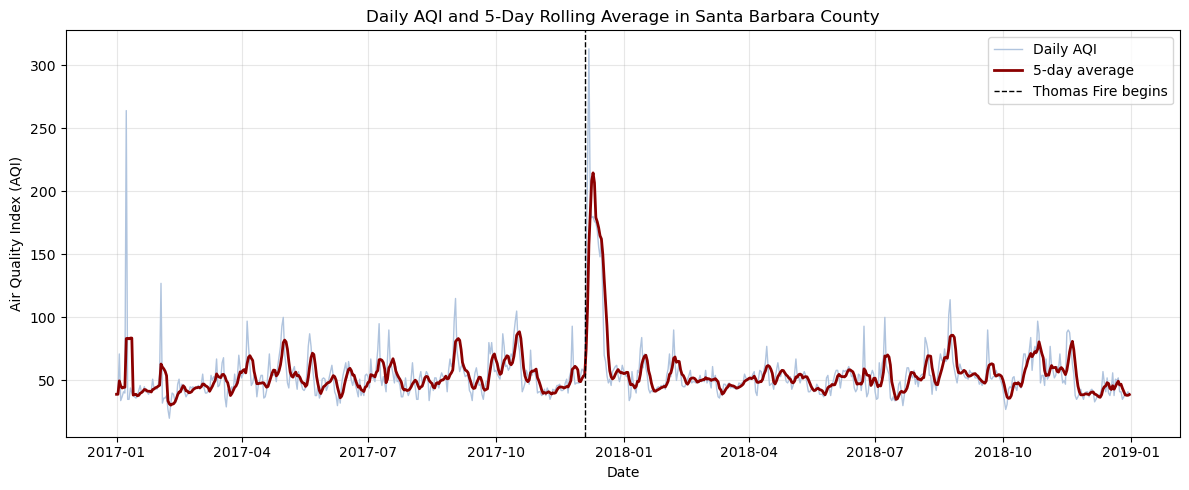

In [37]:
# Create line plot showing daily AQI and 5-day average
import matplotlib.pyplot as plt
import pandas as pd

fig, ax = plt.subplots(figsize=(12, 5))

# Daily AQI in the background
ax.plot(aqi_sb.index, aqi_sb['aqi'],
        color='lightsteelblue', linewidth=1, label='Daily AQI')

# 5-day average on top
ax.plot(aqi_sb.index, aqi_sb['five_day_average'],
        color='darkred', linewidth=2, label='5-day average')

# Mark the start of the Thomas Fire (December 4, 2017)
ax.axvline(pd.Timestamp('2017-12-04'), color='black', linestyle='--',
           linewidth=1, label='Thomas Fire begins')

ax.set_title('Daily AQI and 5-Day Rolling Average in Santa Barbara County')
ax.set_xlabel('Date')
ax.set_ylabel('Air Quality Index (AQI)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [38]:
grader.check_all()

q3_a results: All test cases passed!

q4 results: All test cases passed!

q6a results: All test cases passed!

q8 results: All test cases passed!

q9 results: All test cases passed!

<!-- END QUESTION -->

## 11


Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).